<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [PySAL Spatial Analysis](https://github.com/Query-farm/vgi-pysal)

Spatial weights, autocorrelation tests, map classification, inequality measures, and spatial regression from PySAL, callable from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-pysal/blob/main/notebooks/02_classification_changes_the_map.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-pysal/blob/main/notebooks/README.md)

## The same values can draw different maps

How much of a choropleth comes from the classification rule? Retrieve the worker’s **49 Columbus neighborhood polygons**, then classify the same stored crime-rate column three ways. Inspect class boundaries and populations before interpreting color.

This is the historical **1980 Columbus teaching dataset** bundled with libpysal, not current crime information or a ranking of people. Classification labels are not statistical significance tests. No causal explanation is inferred from a map.

### Choose one change

Edit the parameter below, then restart and run all. The saved default and the final experiment use the same source rows.

In [1]:
CLASS_COUNT = 4  # Experiment: 6

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.50":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.50"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("pysal")
import hashlib
import json
import os
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

theme()
session = connect(globals())
con = session.connection
previous = {name: os.environ.get(name) for name in ["MPLBACKEND", "PYSAL_MODELS_DIR"]}
model_directory = TemporaryDirectory(prefix="pysal-example-models-")
os.environ.update(MPLBACKEND="Agg", PYSAL_MODELS_DIR=model_directory.name)

assert type(CLASS_COUNT) is int and 2 <= CLASS_COUNT <= 7
chart_source = "Historical Columbus 1980 teaching data · libpysal bundled dataset · PySAL v0.1.0\nIdentical values/geometries in each panel; classes do not establish significant clusters."

### Connect the published worker

The short Git-tag command runs the released worker in an isolated environment. Shared setup retrieves verified example files. Computation uses bundled or explicitly invented data; no external account is needed. The model registry is isolated in a temporary directory and removed at cleanup.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pysal' (
  TYPE vgi,
  LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-pysal@v0.1.0 vgi-pysal'
);

,Success


### Retrieve the data once and keep its identity

The worker returns WKB polygons and a stable observation ID. The stored `crime` field is the dataset’s combined residential-burglary and vehicle-theft rate per 1,000 households. Preserve these historical values; SQL’s spatial extension converts geometry only for rendering. Map coordinates retain the teaching dataset’s native axes and are not longitude/latitude.

In [5]:
%%sql
CREATE TABLE neighborhoods AS SELECT id,crime,geom FROM pysal.main.columbus();
INSTALL spatial;
LOAD spatial;
CREATE TABLE outlines AS SELECT id,ST_AsGeoJSON(ST_GeomFromWKB(geom)) AS geometry_json FROM neighborhoods;

,Count


In [6]:
counts = con.execute(
    "SELECT count(*) AS rows,count(DISTINCT id) AS ids,count(crime) AS known,min(crime) AS low,max(crime) AS high FROM neighborhoods"
).df()
display(counts)
assert counts.rows.iloc[0] == counts.ids.iloc[0] == counts.known.iloc[0] == 49
fingerprint = hashlib.sha256(
    con.execute("SELECT id,crime FROM neighborhoods ORDER BY id").df().to_json(orient="records").encode()
).hexdigest()
prose(
    f"All **49 historical observations** have a unique ID and a known rate. Range: **{counts.low.iloc[0]:.2f}–{counts.high.iloc[0]:.2f}**. Source-value fingerprint: `{fingerprint}`. Geometry and values are materialized once."
)

,rows,ids,known,low,high
0,49,49,49,0.178269,68.892044


All **49 historical observations** have a unique ID and a known rate. Range: **0.18–68.89**. Source-value fingerprint: `d15f545d8cb72e7f3c8b6211edcda660c87467ec8ddb2a2b2a6928d3775d8313`. Geometry and values are materialized once.

### Compare three definitions of a class

**Quantiles** aim for similar class populations; **equal intervals** use equal numeric widths; **Fisher–Jenks** minimizes within-class squared variation for this one-dimensional value distribution. A shared class number denotes an ordinal bin, not the same numeric threshold across methods. Each call uses the same explicit ID order.

In [7]:
%%sql
CREATE TABLE quantile_classes AS SELECT * FROM pysal.main.quantiles((SELECT id,crime FROM neighborhoods ORDER BY id),value:='crime',id:='id',k:={{CLASS_COUNT}});
CREATE TABLE interval_classes AS SELECT * FROM pysal.main.equal_interval((SELECT id,crime FROM neighborhoods ORDER BY id),value:='crime',id:='id',k:={{CLASS_COUNT}});
CREATE TABLE jenks_classes AS SELECT * FROM pysal.main.fisher_jenks((SELECT id,crime FROM neighborhoods ORDER BY id),value:='crime',id:='id',k:={{CLASS_COUNT}});
CREATE TABLE assigned AS
SELECT 'Quantiles' AS method,* FROM quantile_classes UNION ALL SELECT 'Equal interval',* FROM interval_classes UNION ALL SELECT 'Fisher–Jenks',* FROM jenks_classes;
CREATE TABLE class_summary AS SELECT method,class+1 AS class_number,count(*) AS observations,min(n.crime) AS observed_min,max(n.crime) AS observed_max,min(a.upper_bound) AS upper_bound
FROM assigned a JOIN neighborhoods n USING(id) GROUP BY method,class;

,Count


In [8]:
%%sql summary <<
SELECT * FROM class_summary ORDER BY method,class_number;

In [9]:
display(summary)
disagreements = con.execute(
    "SELECT count(*) FROM quantile_classes q JOIN interval_classes i USING(id) JOIN jenks_classes j USING(id) WHERE q.class<>i.class OR q.class<>j.class"
).fetchone()[0]
prose(
    f"With **{CLASS_COUNT} requested classes**, **{disagreements}/49 observations** receive different ordinal class numbers across methods. Equal-width bins need not hold equal numbers of observations. Read the table’s actual boundaries before comparing colors."
)

,method,class_number,observations,observed_min,observed_max,upper_bound
0,Equal interval,1,7,0.178269,16.530533,17.356713
1,Equal interval,2,18,17.677214,34.000835,34.535156
2,Equal interval,3,13,36.663612,50.731510,51.713600
3,Equal interval,4,11,52.794430,68.892044,68.892044
4,Fisher–Jenks,1,2,0.178269,0.223797,0.223797
5,Fisher–Jenks,2,18,14.305556,29.028488,29.028488
6,Fisher–Jenks,3,16,30.515917,46.716129,46.716129
7,Fisher–Jenks,4,13,48.585487,68.892044,68.892044
8,Quantiles,1,13,0.178269,20.048504,20.048504
9,Quantiles,2,12,22.541491,34.000835,34.000835


With **4 requested classes**, **18/49 observations** receive different ordinal class numbers across methods. Equal-width bins need not hold equal numbers of observations. Read the table’s actual boundaries before comparing colors.

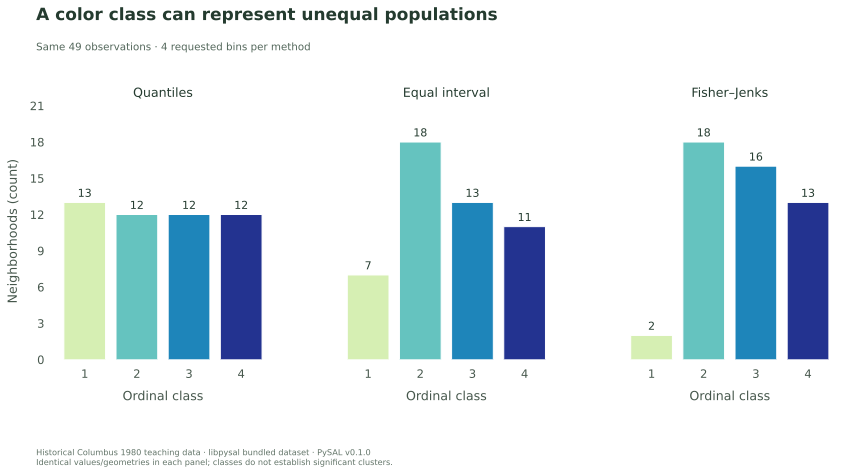

In [10]:
from matplotlib.ticker import MaxNLocator

methods = ["Quantiles", "Equal interval", "Fisher–Jenks"]
colors = plt.get_cmap("YlGnBu")(np.linspace(0.20, 0.88, CLASS_COUNT))
fig, axes = plt.subplots(1, 3, figsize=(12.4, 7), sharey=True)
for ax, method in zip(axes, methods, strict=True):
    group = summary[summary.method.eq(method)].set_index("class_number").reindex(range(1, CLASS_COUNT + 1))
    values = group.observations.fillna(0)
    bars = ax.bar(range(1, CLASS_COUNT + 1), values, color=colors)
    ax.bar_label(bars, fmt="%.0f", padding=3)
    ax.set(title=method, xlabel="Ordinal class", xticks=range(1, CLASS_COUNT + 1))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("Neighborhoods (count)")
axes[0].set_ylim(0, summary.observations.max() * 1.18)
finish(
    fig,
    "A color class can represent unequal populations",
    f"Same 49 observations · {CLASS_COUNT} requested bins per method",
    chart_source,
    name=f"class-populations-{CLASS_COUNT}",
)

### Keep geometry fixed and change only the classification

All three maps use identical outlines and the same ordered color palette. Numeric boundaries differ between panels, so compare membership against the preceding table. An area colored darker is merely in a higher bin for that rule; its area, population and uncertainty are not encoded.

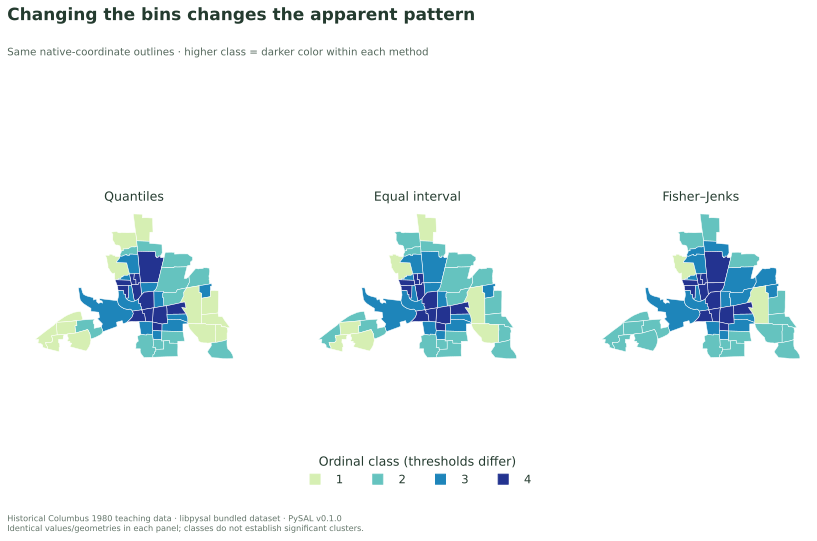

In [11]:
from matplotlib.patches import Polygon

maps = con.execute(
    "SELECT a.*,o.geometry_json FROM assigned a JOIN outlines o USING(id) ORDER BY method,id"
).df()
fig, axes = plt.subplots(1, 3, figsize=(12.4, 8))
for ax, method in zip(axes, methods, strict=True):
    for row in maps[maps.method.eq(method)].to_dict("records"):
        geometry = json.loads(row["geometry_json"])
        polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
        for polygon in polygons:
            ax.add_patch(
                Polygon(polygon[0], facecolor=colors[row["class"]], edgecolor="white", linewidth=0.5)
            )
            for hole in polygon[1:]:
                ax.add_patch(Polygon(hole, facecolor="white", edgecolor="white", linewidth=0.5))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.set_title(method)
    ax.set_axis_off()
legend = [
    plt.Line2D([0], [0], marker="s", markersize=10, linestyle="", color=color, label=str(i + 1))
    for i, color in enumerate(colors)
]
fig.legend(
    handles=legend,
    title="Ordinal class (thresholds differ)",
    loc="lower center",
    bbox_to_anchor=(0.53, 0.12),
    ncol=CLASS_COUNT,
    frameon=False,
)
finish(
    fig,
    "Changing the bins changes the apparent pattern",
    "Same native-coordinate outlines · higher class = darker color within each method",
    chart_source,
    name=f"class-maps-{CLASS_COUNT}",
)

### Verify coverage and containment

The classification must retain all keys once per method, produce valid class indices, and place every observation at or below its returned inclusive upper bound. The map is a re-expression of the same observations, not additional evidence.

In [12]:
%%sql checks <<
SELECT 'All methods retain each ID exactly once' AS check_name,count(*)=147 AND count(DISTINCT(method,id))=147 AS passed FROM assigned
UNION ALL SELECT 'No unknown IDs',count(*)=0 FROM assigned a ANTI JOIN neighborhoods n USING(id)
UNION ALL SELECT 'Valid class indices',bool_and(class>=0 AND class<{{CLASS_COUNT}}) FROM assigned
UNION ALL SELECT 'Observed values fit inclusive upper bounds',bool_and(n.crime<=a.upper_bound+1e-10) FROM assigned a JOIN neighborhoods n USING(id)
UNION ALL SELECT 'One upper boundary per occupied bin',count(*)=0 FROM (SELECT method,class FROM assigned GROUP BY method,class HAVING count(DISTINCT upper_bound)<>1)
UNION ALL SELECT 'Each method accounts for 49 observations',bool_and(n=49) FROM (SELECT method,sum(observations) AS n FROM class_summary GROUP BY method)
UNION ALL SELECT 'Geometry roster is complete',count(*)=49 AND count(geometry_json)=49 FROM outlines;

In [13]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(
    f"All **{len(checks)} checks** pass. The class assignment changes while the 49-row source population remains fixed."
)

,check_name,passed
0,All methods retain each ID exactly once,True
1,No unknown IDs,True
2,Valid class indices,True
3,Observed values fit inclusive upper bounds,True
4,One upper boundary per occupied bin,True
5,Each method accounts for 49 observations,True
6,Geometry roster is complete,True


All **7 checks** pass. The class assignment changes while the 49-row source population remains fixed.

### Experiment: request six classes

Change only `CLASS_COUNT=4` to **6**. Compare the bin counts, boundary table and three maps. The source fingerprint, IDs and geometries must remain unchanged. A more detailed palette does not imply finer measurement, more population coverage or stronger evidence of a cluster.

Source: [libpysal Columbus metadata](https://github.com/pysal/libpysal/tree/v4.15.1/libpysal/examples/columbus). The next notebooks examine distribution summaries and model lifecycle separately.

In [14]:
session.close()
model_directory.cleanup()
for name, value in previous.items():
    if value is None:
        os.environ.pop(name, None)
    else:
        os.environ[name] = value

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-pysal](https://github.com/Query-farm/vgi-pysal)